# Log or power? Growth of the 143 slow survivors, 1e7 to 1e11 steps

## Question
Of the 702 rules still unresolved at 1e11 steps, 143 grow their bounding box very slowly (`results/classes.csv`). The first test of
them (P3) asked whether they stay within 5% from 1e11 to 2e11 and failed on one of eight. Is the side of such a rule better described as
`a + b log10 t` (H-log), as `C t^alpha` with small alpha (H-power), or as constant (H-const)? Registered in `README.md`, Amendment A1,
before any model was fitted (commit `b1014be`). Lab notebook: `NOTEBOOK.md`.

## Assumptions
* Side = max(width, height) of the visited box at exactly 10^k steps, k = 7..11, from five committed census files (listed in the provenance cell).
* Noise: independent Gaussian, sigma = max(1, 0.03 y) cells. A guess; the log-likelihood-like score is chi2 weighted by it.
* Per-rule label from chi2 and AIC; the aggregate verdict (P3) is a parametric bootstrap, which this notebook does **not** rerun (it reads the committed
  `growth_fit.txt`, produced by `scripts/growth_fit.py`, seed 20261112).
* H-log was suggested by a look at the same four decades; the 1e7 box is the only out-of-sample data.

## Provenance

In [1]:
import hashlib, subprocess, datetime, math, re
from pathlib import Path
import numpy as np, polars as pl

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
EXP = ROOT / "experiments/active/2026-11-survivor-slow-growers"
INPUTS = [EXP / "results/growth_fit.csv", EXP / "results/growth_fit.txt", EXP / "results/classes.csv", EXP / "scripts/growth_fit.py"]
assert all(p.exists() for p in INPUTS)
sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print("git", sha, "| registration b1014be, script e357179, results efeae5b")
for p in INPUTS:
    print(hashlib.sha256(p.read_bytes()).hexdigest()[:16], p.relative_to(ROOT))

git efeae5b | registration b1014be, script e357179, results efeae5b
096595257ceb7f7a experiments/active/2026-11-survivor-slow-growers/results/growth_fit.csv
c83df57d513dbd17 experiments/active/2026-11-survivor-slow-growers/results/growth_fit.txt
9d867159426bae92 experiments/active/2026-11-survivor-slow-growers/results/classes.csv
7f2292e54fe05ac7 experiments/active/2026-11-survivor-slow-growers/scripts/growth_fit.py


## Data and method
One row per slow rule: sides at 1e7..1e11, fitted chi2 for the three models, fitted alpha, log intercept and slope, and the 4-point label.

In [2]:
d = pl.read_csv(EXP / "results/growth_fit.csv")
cls = pl.read_csv(EXP / "results/classes.csv")
assert d.height == 143 and set(d["rule"]) == set(cls.filter(pl.col("cls") == "slow")["rule"])
print(d.select("rule", "s1e7", "s1e8", "s1e9", "s1e10", "s1e11", "chi2_log", "chi2_power", "alpha_hat", "log_b", "label4").head(8))
print("rules:", d.height, "| side at 1e11: median", d["s1e11"].median(), "min", d["s1e11"].min(), "max", d["s1e11"].max())

shape: (8, 11)
┌────────────┬──────┬──────┬──────┬───┬────────────┬───────────┬─────────┬───────────┐
│ rule       ┆ s1e7 ┆ s1e8 ┆ s1e9 ┆ … ┆ chi2_power ┆ alpha_hat ┆ log_b   ┆ label4    │
│ ---        ┆ ---  ┆ ---  ┆ ---  ┆   ┆ ---        ┆ ---       ┆ ---     ┆ ---       │
│ str        ┆ i64  ┆ i64  ┆ i64  ┆   ┆ f64        ┆ f64       ┆ f64     ┆ str       │
╞════════════╪══════╪══════╪══════╪═══╪════════════╪═══════════╪═════════╪═══════════╡
│ RLLLLLLLLR ┆ 20   ┆ 28   ┆ 28   ┆ … ┆ 16.8972    ┆ 0.03504   ┆ 2.2859  ┆ ambiguous │
│ RLLLLLLLR  ┆ 20   ┆ 28   ┆ 28   ┆ … ┆ 3.7888     ┆ 0.04004   ┆ 2.762   ┆ ambiguous │
│ RLLLLLLLRL ┆ 36   ┆ 40   ┆ 50   ┆ … ┆ 4.5814     ┆ 0.06206   ┆ 7.4489  ┆ ambiguous │
│ RLLLLLLR   ┆ 24   ┆ 28   ┆ 36   ┆ … ┆ 11.2929    ┆ 0.05806   ┆ 4.7389  ┆ ambiguous │
│ RLLLLLLRL  ┆ 42   ┆ 52   ┆ 60   ┆ … ┆ 0.5095     ┆ 0.06707   ┆ 10.0592 ┆ ambiguous │
│ RLLLLLLRRR ┆ 44   ┆ 52   ┆ 60   ┆ … ┆ 1.1284     ┆ 0.06406   ┆ 9.5665  ┆ ambiguous │
│ RLLLLLR    ┆ 26   ┆ 32   ┆

## Results
The predictions, recomputed from the CSV (these must equal the README).

In [3]:
n = d.height
p1 = (d["chi2_const"] > 7.815).sum(); p2 = (d["chi2_log"] <= 5.991).sum()
print(f"P1 (registered >= 80%): chi2_const > 7.815 in {p1}/{n}; P2 (>= 75%): chi2_log <= 5.991 in {p2}/{n} (power: {(d['chi2_power'] <= 5.991).sum()}/{n})")
print("labels (4 points):", d["label4"].value_counts().sort("label4").rows())
print("labels (5 points):", d["label5"].value_counts().sort("label5").rows())
y7 = d["s1e7"].to_numpy().astype(float)
eL = np.abs(y7 - d["pred1e7_log"].to_numpy()); eP = np.abs(y7 - d["pred1e7_power"].to_numpy())
nl, npw = int((eL < eP).sum()), int((eL > eP).sum()); N = nl + npw; k = min(nl, npw)
p4 = min(1.0, 2 * sum(math.comb(N, i) for i in range(k + 1)) / 2.0 ** N)
print(f"P4 backcast to 1e7: log closer in {nl}, power closer in {npw}; two-sided binomial p = {p4:.2g}; median |err| log {np.median(eL):.2f}, power {np.median(eP):.2f}")
print(f"alpha_hat median {d['alpha_hat'].median():.4f}; log slope median {d['log_b'].median():.2f} cells per decade; sum D = {d['D'].sum():+.2f}")
txt = (EXP / "results/growth_fit.txt").read_text()
print(re.search(r"^P3:.*$", txt, re.M).group(0))
assert (p1, p2, nl, npw) == (143, 123, 108, 35) and d["label4"].value_counts().filter(pl.col("label4") == "ambiguous")["count"][0] == 135

P1 (registered >= 80%): chi2_const > 7.815 in 143/143; P2 (>= 75%): chi2_log <= 5.991 in 123/143 (power: 122/143)
labels (4 points): [('ambiguous', 135), ('log', 6), ('power', 2)]
labels (5 points): [('ambiguous', 104), ('log', 29), ('power', 10)]
P4 backcast to 1e7: log closer in 108, power closer in 35; two-sided binomial p = 7.4e-10; median |err| log 1.64, power 3.25
alpha_hat median 0.0591; log slope median 8.73 cells per decade; sum D = +71.77
P3: S_obs +71.77; LOG arm S* mean +87.73 (5-95%: +56.9 +118.9); POWER arm S* mean -91.75 (5-95%: -123.5 -59.7); p_pow 0.0000, p_log 0.1940 -> LOG favoured -> P3 HOLD


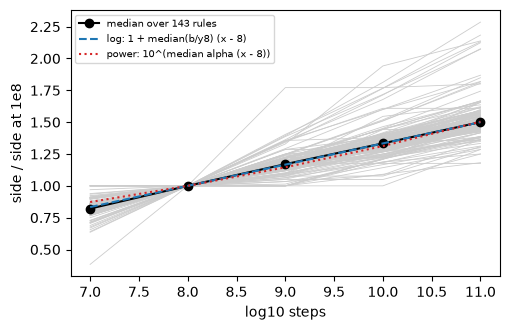

In [4]:
import matplotlib
import matplotlib.pyplot as plt
x = np.arange(7, 12)
Y = d.select("s1e7", "s1e8", "s1e9", "s1e10", "s1e11").to_numpy().astype(float)
R = Y / Y[:, [1]]
fig, ax = plt.subplots(figsize=(5.2, 3.4))
for r in R: ax.plot(x, r, color="0.8", lw=0.6)
ax.plot(x, np.median(R, 0), "k-o", label="median over 143 rules")
b = d["log_b"].to_numpy() / d["s1e8"].to_numpy(); a = d["alpha_hat"].to_numpy()
ax.plot(x, 1 + np.median(b) * (x - 8), "C0--", label="log: 1 + median(b/y8) (x - 8)")
ax.plot(x, 10 ** (np.median(a) * (x - 8)), "C3:", label="power: 10^(median alpha (x - 8))")
ax.set_xlabel("log10 steps"); ax.set_ylabel("side / side at 1e8"); ax.legend(fontsize=7); fig.tight_layout()
plt.show()

**What this shows.** Constant boxes are refuted for all 143 rules over 1e8 to 1e11 (and the cube-root control is refuted for all). In aggregate, power is
rejected at the registered noise model (bootstrap p < 0.0005) and the log curve is not (p = 0.19); the unseen 1e7 box is closer to the log backcast in
108 of 143 rules (p about 7e-10). Per rule, 135 of 143 labels are ambiguous: the two families fit individual rules about equally well.

**What it does not show.** Nothing about t beyond 1e11; no individual rule is certified as log; powers below alpha about 0.04 cannot be separated from log
by this design (synthetic calibration in `growth_fit.txt`). The bootstrap treats correlated rules as independent. The 3% + 1-cell sigma is a guess
(G1: median chi2 0.49 against a nominal 1.39, so it is somewhat wide).

## Caveats
* Partly confirmatory: H-log was suggested by the same four decades; only the backcast is out of sample, and it was read once.
* Both fits slightly over-predict the 2e11 side of 6 of 8 sampled rules and the log fit over-predicts the 1e7 box by about 1 cell on average (post hoc: the curve may be a little flatter than log).

## Next steps
A 1e12 run of the 8 P3 rules (about 4.5 h each on the tiled backend) against a registered log versus saturating prediction would test a bend; an exact-recurrence check would be needed for "bounded". Neither is registered.